# Agrupando colores

Vamos a crear imagenes con una cantidad fija de colores

#### 1. Importa las librerias
Vamos a necesitar `KMeans` de `sklearn.cluster`, `imread` de `matplotlib.image`, `matplotlib.pyplot` y `numpy`


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

#### 2. Lee una imagen
Utiliza alguna foto que tengas en tu ordenador y leela con la función `imread`

Consejo: utiliza una imagen pequeña si no quieres tardar una eternidad en que se ejecute el kmeans

In [2]:
image = plt.imread('data/ejer_kmeans.png')
image.shape

(764, 1499, 3)

Muestra la imagen para ver que se ha cargado bien

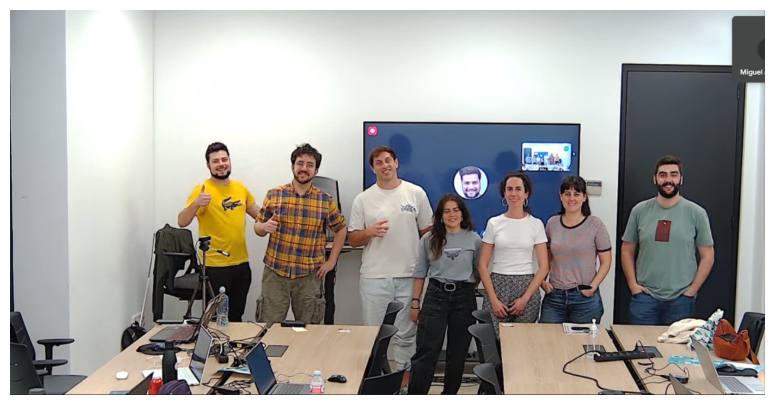

In [3]:

plt.figure(figsize=(10, 5))
plt.imshow(image)
plt.axis('off')
plt.show()


#### 3. Modifica la estructura de la imagen
Queremos que cada pixel sea una observación por lo que tenemos que transformar nuestra imagen de un vector de forma (alto, ancho, color) a (alto x ancho, color). Color será siempre 3, que son los tres canales de los colores.

Ej: (300, 400, 3) -> (120000, 3)

In [5]:

# Guardamos las dimensiones originales
alto, ancho, canales = image.shape

# Transformamos la imagen en una matriz de píxeles
image_reshaped = image.reshape(-1, 3)

# Comprobamos las dimensiones
print("Forma original:", image.shape)
print("Forma transformada:", image_reshaped.shape)


Forma original: (764, 1499, 3)
Forma transformada: (1145236, 3)


#### 4. K-means
Haz un k-means con la imagen de entrada (Con la nueva forma que le hemos dado). K será el número de colores que quieras que tenga tu imagen de salida

In [6]:
# Creamos el modelo K-Means
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

# Entrenamos el modelo
kmeans.fit(image_reshaped)

,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",8
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float32](8, 3)","[[0.2

#### 5. Sustituye cada valor por su centroide

Una vez hemos entrenado el kmeans entre otros parametros de salida tiene `cluster_centers_` y `labels_`. Utilizlos para crear una nueva imagen (recuerda que las imagenes simplemente son vectores numéricos) en la que cada pixel se sustituye por su centroide correspondiente.

In [8]:
# Sustituimos cada píxel por el color de su centroide
image_compressed = kmeans.cluster_centers_[kmeans.labels_]

#### 6. Modifica la estructura de la imagen
Para trabajar con el k-means requeriamos que la imagen original fuese un solo vector, ahora como queremos volver a tener la imagen para volver mostrarla debemos hacer el proceso inverso a el paso 3. (Si has guardado la forma de la imagen original te será más facil hacer este paso)

In [9]:
# Recuperamos las dimensiones originales de la imagen
image_compressed = image_compressed.reshape(image.shape)

# Comprobamos las dimensiones
print("Imagen original:", image.shape)
print("Imagen comprimida:", image_compressed.shape)

Imagen original: (764, 1499, 3)
Imagen comprimida: (764, 1499, 3)


#### 7. Muestra y guarda en tu ordenador la imagen resultante

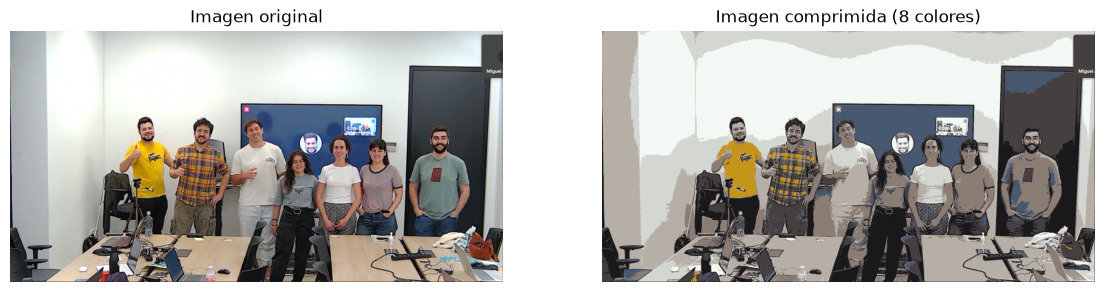

In [10]:
# Creamos una figura con dos imágenes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mostramos la imagen original
axes[0].imshow(image)
axes[0].set_title("Imagen original")
axes[0].axis('off')

# Mostramos la imagen comprimida
axes[1].imshow(image_compressed)
axes[1].set_title("Imagen comprimida (8 colores)")
axes[1].axis('off')

plt.show()

In [11]:
# Guardamos la imagen comprimida
plt.imsave('data/imagen_comprimida.png', image_compressed)

#### 8. Crea una función
Crea una función que tenga como argumentos de entrada una imagen, el numero de colores que quieres que tenga, y si se quiere guardar o mostrar por pantalla

In [12]:
def comprimir_imagen(image, n_colores=8):
    # Obtenemos las dimensiones de la imagen
    alto, ancho, canales = image.shape

    # Convertimos la imagen en una matriz de píxeles RGB
    image_reshaped = image.reshape(-1, canales)

    # Creamos y entrenamos el modelo K-Means
    kmeans = KMeans(
        n_clusters=n_colores,
        random_state=42,
        n_init=10
    )
    kmeans.fit(image_reshaped)

    # Sustituimos cada píxel por el color de su centroide
    image_compressed = kmeans.cluster_centers_[kmeans.labels_]

    # Recuperamos las dimensiones originales
    image_compressed = image_compressed.reshape(image.shape)

    return image_compressed

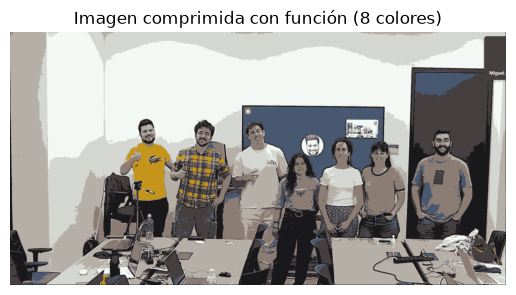

In [13]:
# Comprimimos la imagen utilizando 8 colores
imagen_resultado = comprimir_imagen(image, n_colores=8)

# Mostramos el resultado
plt.imshow(imagen_resultado)
plt.title("Imagen comprimida con función (8 colores)")
plt.axis('off')
plt.show()

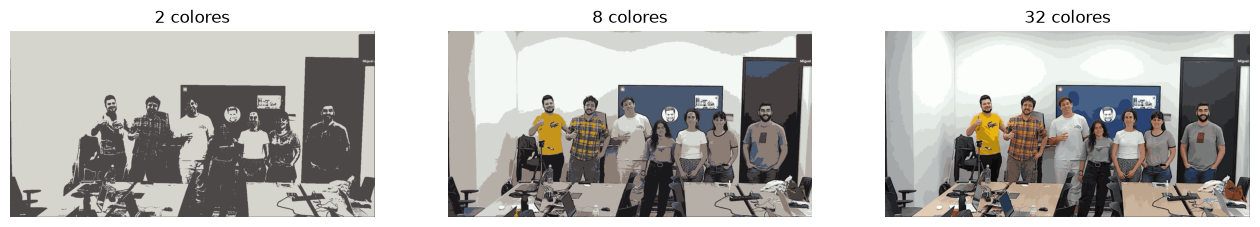

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, n in zip(axes, [2, 8, 32]):
    resultado = comprimir_imagen(image, n_colores=n)
    ax.imshow(resultado)
    ax.set_title(f"{n} colores")
    ax.axis('off')

plt.show()